# Семинар 4.4 Снижение размерности данных

In [1]:
from sklearn.datasets import fetch_openml
import numpy as np
import matplotlib.pyplot as plt

X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
y = np.array(y, dtype=int)

In [2]:
X.shape

(70000, 784)

In [3]:
np.sqrt(X.shape[1])

np.float64(28.0)

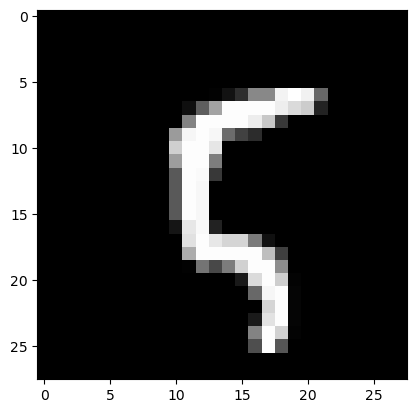

In [4]:
plt.imshow(X[100].reshape(28, 28),cmap="gray")

In [5]:
import scipy.sparse.linalg as spsplin
u, s, v = spsplin.svds(X - X.mean(axis=0)[None, :], k=2)

In [6]:
uu = u@np.diag(s)

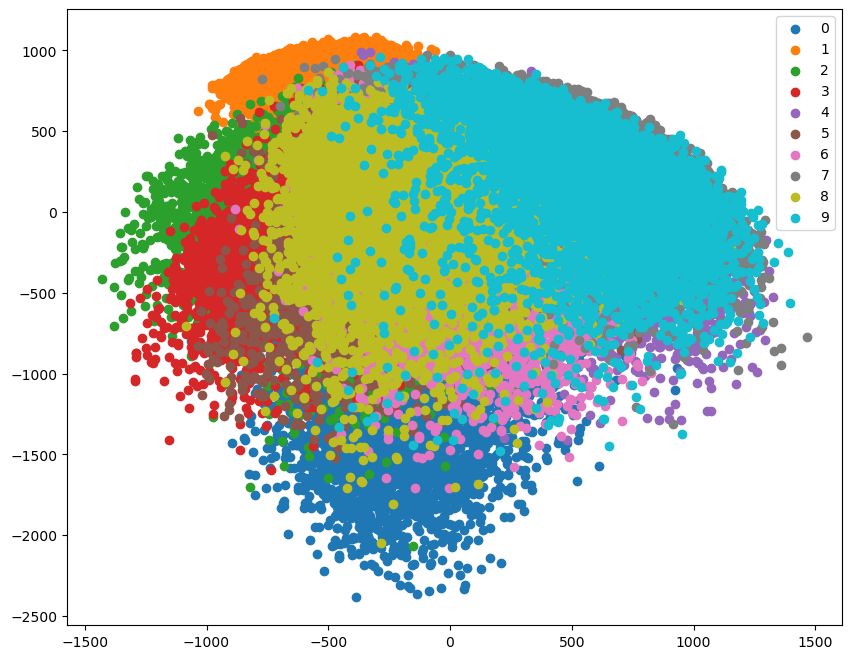

In [7]:
plt.figure(figsize=(10, 8))
for c in np.unique(y):
    plt.scatter(uu[y == c, 0], uu[y == c, 1], label="{}".format(c))
plt.legend()

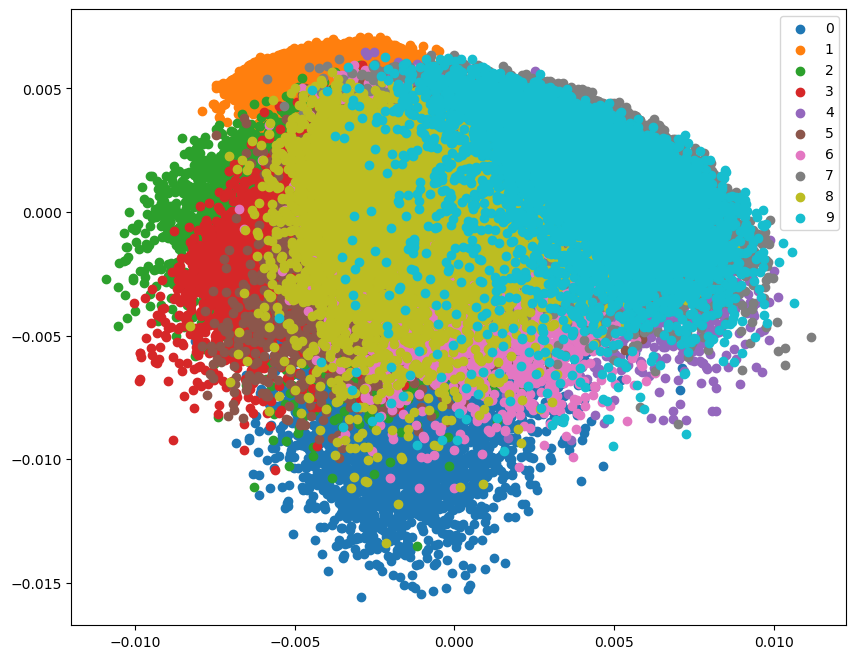

In [8]:
plt.figure(figsize=(10, 8))
for c in np.unique(y):
    plt.scatter(u[y == c, 0], u[y == c, 1], label="{}".format(c))
plt.legend()

In [9]:
import sklearn.manifold as sklman
tsne = sklman.TSNE(verbose=True)
X_2d = tsne.fit_transform(X[:4000, :])

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 4000 samples in 0.002s...
[t-SNE] Computed neighbors for 4000 samples in 0.257s...
[t-SNE] Computed conditional probabilities for sample 1000 / 4000
[t-SNE] Computed conditional probabilities for sample 2000 / 4000
[t-SNE] Computed conditional probabilities for sample 3000 / 4000
[t-SNE] Computed conditional probabilities for sample 4000 / 4000
[t-SNE] Mean sigma: 581.531552
[t-SNE] KL divergence after 250 iterations with early exaggeration: 80.305847
[t-SNE] KL divergence after 1000 iterations: 1.380143


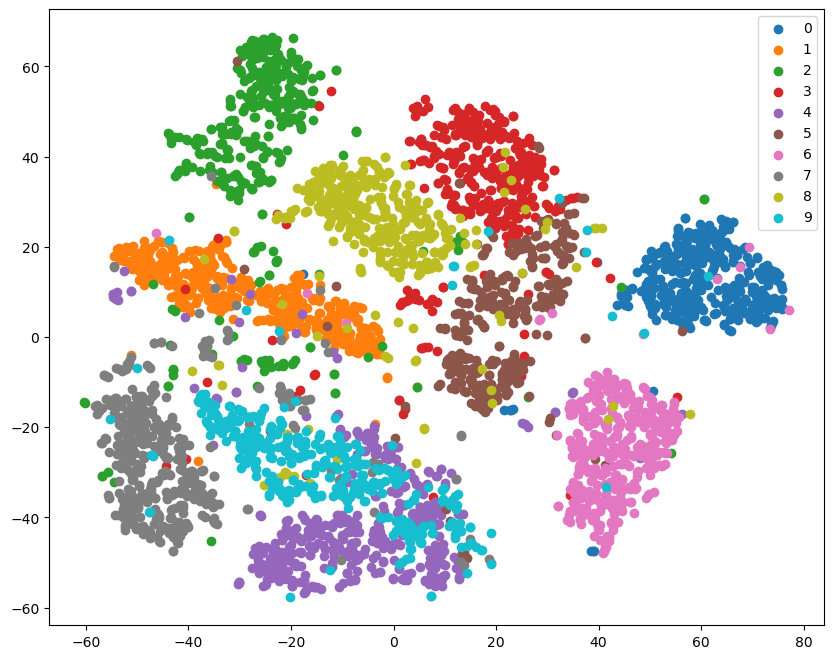

In [10]:
plt.figure(figsize=(10, 8))
for c in np.unique(y):
    plt.scatter(X_2d[y[:4000] == c, 0], X_2d[y[:4000] == c, 1], label="{}".format(c))
plt.legend()